# Flickr8k Caption Exploration and Label Vocabulary

Flickr8k provides five free-text captions per image but no labels. This notebook cleans the captions, analyses them and derives the label vocabulary (the 100 most frequent content tokens) that the classifier in `02_model_training.ipynb` is trained on.

**Sections**
1. Setup
2. Load and validate the captions
3. Build the clean caption table
4. Descriptive statistics
5. Tokenization and top tokens
6. Label vocabulary
7. TF-IDF keywords per image
8. CSV exports

## 1. Setup

In [1]:
import re
from collections import Counter, defaultdict
from math import log

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paths
CAPTIONS_PATH = "captions.txt"
CLEAN_CSV_PATH = "dataset/captions.csv"
TOPTOKENS_IMAGE_CSV_PATH = "dataset/top_tokens_with_images.csv"
KEYWORDS_PER_IMAGE_CSV_PATH = "dataset/keywords_per_image.csv"

pd.set_option("display.max_rows", 10)
pd.set_option("display.width", 120)

## 2. Load and validate the captions

In [2]:
df_raw = pd.read_csv(CAPTIONS_PATH)
assert set(df_raw.columns) == {"image", "caption"}, f"Unexpected columns: {df_raw.columns.tolist()}"

# Normalise whitespace
df_raw["caption"] = df_raw["caption"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df_raw.sample(5)

,image,caption
8469,2389107995_ec756f3514.jpg,The dog is swimming in the water .
32622,3612485611_12dd7742f7.jpg,Two men jumping outside on the grass .
32458,3605676864_0fb491267e.jpg,The boy laughed as he swam in the pool .
24979,330849796_c575c3108a.jpg,The girl is sleeping in the seat .
5847,2191453879_11dfe2ba3a.jpg,A little boy in shorts and blue t-shirt runs o...


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40455 entries, 0 to 40454
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   image    40455 non-null  object
 1   caption  40455 non-null  object
dtypes: object(2)
memory usage: 632.2+ KB


## 3. Build the clean caption table

One row per caption with a running caption index per image.

In [4]:
df = df_raw.copy()
df["caption_idx"] = df.groupby("image").cumcount()
df = df.rename(columns={"image": "image_id"})
df = df[["image_id", "caption_idx", "caption"]].sort_values(["image_id", "caption_idx"]).reset_index(drop=True)
df.head(10)

,image_id,caption_idx,caption
0,1000268201_693b08cb0e.jpg,0,A child in a pink dress is climbing up a set o...
1,1000268201_693b08cb0e.jpg,1,A girl going into a wooden building .
2,1000268201_693b08cb0e.jpg,2,A little girl climbing into a wooden playhouse .
3,1000268201_693b08cb0e.jpg,3,A little girl climbing the stairs to her playh...
4,1000268201_693b08cb0e.jpg,4,A little girl in a pink dress going into a woo...
5,1001773457_577c3a7d70.jpg,0,A black dog and a spotted dog are fighting
6,1001773457_577c3a7d70.jpg,1,A black dog and a tri-colored dog playing with...
7,1001773457_577c3a7d70.jpg,2,A black dog and a white dog with brown spots a...
8,1001773457_577c3a7d70.jpg,3,Two dogs of different breeds looking at each o...
9,1001773457_577c3a7d70.jpg,4,Two dogs on pavement moving toward each other .


## 4. Descriptive statistics

rows_total: 40455
images_total: 8091
captions_per_image_distribution: {5: 8091}
caption_words_avg: 11.78
caption_words_p50: 11.0
caption_words_p90: 17.0


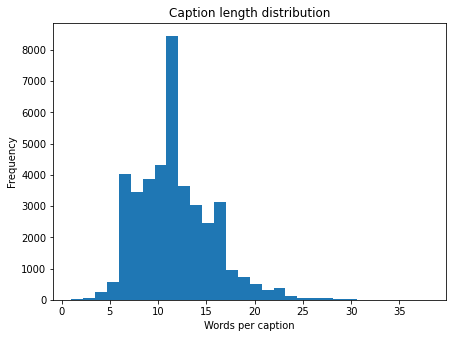

In [5]:
num_rows = len(df)
num_images = df["image_id"].nunique()
caps_per_img_counts = df.groupby("image_id").size().value_counts().sort_index()
word_counts = df["caption"].str.split().apply(len)

summary = {
    "rows_total": int(num_rows),
    "images_total": int(num_images),
    "captions_per_image_distribution": caps_per_img_counts.to_dict(),
    "caption_words_avg": float(round(word_counts.mean(), 2)),
    "caption_words_p50": float(word_counts.median()),
    "caption_words_p90": float(word_counts.quantile(0.9)),
}
for key, value in summary.items():
    print(f"{key}: {value}")

# Caption length distribution
word_counts.plot(kind="hist", bins=30)
plt.title("Caption length distribution")
plt.xlabel("Words per caption")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

**Findings**
- 40,455 captions for 8,091 unique images
- Every image has exactly five captions
- Captions are 11.8 words long on average (median 11, 90th percentile 17)

## 5. Tokenization and top tokens

Lowercasing, removal of punctuation, digits, stopwords and tokens with fewer than three characters.

In [6]:
STOPWORDS = set("""
a an and are as at be by for from has have he her hers him his i in is it its
it's itself me my of on our ours she that the their them there they this to was
we were will with you your yours not into over under near while up down out
""".split())


def tokenize(text, stopwords=STOPWORDS):
    t = re.sub(r"[^a-z0-9\s]", " ", text.lower())
    return [w for w in t.split() if w not in stopwords and not w.isdigit() and len(w) > 2]


tokens = df["caption"].apply(tokenize)
freq = Counter(w for toks in tokens for w in toks)
top_terms_df = pd.DataFrame(freq.most_common(50), columns=["token", "count"])
top_terms_df.head(20)

,token,count
0,dog,8138
1,man,7274
2,two,5642
3,white,3959
4,black,3848
...,...,...
15,dogs,2125
16,running,2073
17,through,2032
18,playing,2008


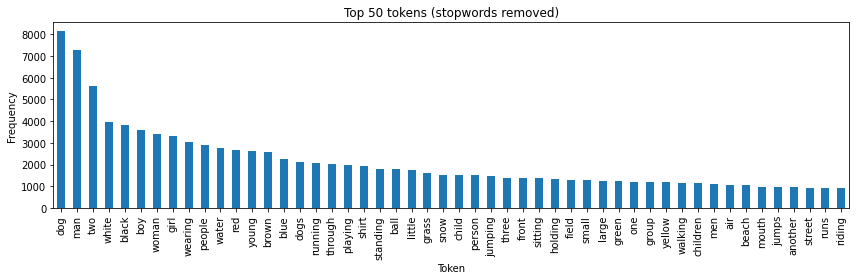

In [7]:
top_terms_df.set_index("token")["count"].plot(kind="bar", figsize=(12, 4))
plt.title("Top 50 tokens (stopwords removed)")
plt.xlabel("Token")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 6. Label vocabulary

The 100 most frequent tokens become the labels. For each token, the number of captions and the number of distinct images it appears in are recorded.

In [8]:
# Map each token to the images it appears in
token_to_images = defaultdict(set)
for _, row in df.iterrows():
    for tok in tokenize(row["caption"]):
        token_to_images[tok].add(row["image_id"])

rows = [
    {"token": tok, "caption_count": cap_count, "image_count": len(token_to_images[tok])}
    for tok, cap_count in freq.most_common(100)
]
df_tokens = pd.DataFrame(rows)
print(df_tokens.head(20))

      token  caption_count  image_count
0       dog           8138         1814
1       man           7274         2470
2       two           5642         1984
3     white           3959         2007
4     black           3848         1835
..      ...            ...          ...
15     dogs           2125          605
16  running           2073         1020
17  through           2032         1235
18  playing           2008         1255
19    shirt           1962         1189

[20 rows x 3 columns]


## 7. TF-IDF keywords per image

A lightweight TF-IDF over the merged captions of each image, implemented without additional NLP libraries.

In [9]:
# One document per image: its five captions merged
docs = df.groupby("image_id")["caption"].apply(lambda s: " ".join(s.tolist())).to_dict()
docs_tokens = {img: tokenize(text) for img, text in docs.items()}

# Document frequency per term
dfreq = Counter()
for toks in docs_tokens.values():
    dfreq.update(set(toks))

N = len(docs_tokens)


def tfidf_score(term, toks):
    tf = toks.count(term) / max(1, len(toks))
    idf = log((N + 1) / (1 + dfreq[term])) + 1.0
    return tf * idf


# Top-k keywords per image
K = 8
records = []
for img, toks in docs_tokens.items():
    if not toks:
        records.append({"image_id": img, "keywords": ""})
        continue
    scored = sorted(((w, tfidf_score(w, toks)) for w in set(toks)), key=lambda x: x[1], reverse=True)[:K]
    records.append({"image_id": img, "keywords": ", ".join(w for w, _ in scored)})

tfidf_df = pd.DataFrame(records).sort_values("image_id")
tfidf_df.head(10)

,image_id,keywords
0,1000268201_693b08cb0e.jpg,"playhouse, wooden, climbing, stairs, girl, goi..."
1,1001773457_577c3a7d70.jpg,"each, dog, other, road, breeds, black, tri, dogs"
2,1002674143_1b742ab4b8.jpg,"rainbow, pigtails, girl, painting, front, pain..."
3,1003163366_44323f5815.jpg,"bench, dog, lays, man, tied, also, sitting, lies"
4,1007129816_e794419615.jpg,"glasses, hat, orange, man, crocheted, blitz, g..."
5,1007320043_627395c3d8.jpg,"ropes, playground, rope, climbs, child, grips,..."
6,1009434119_febe49276a.jpg,"boston, fence, terrier, grass, running, white,..."
7,1012212859_01547e3f17.jpg,"shore, ball, shakes, dog, water, head, orange,..."
8,1015118661_980735411b.jpg,"overalls, wall, boy, street, stone, aross, sto..."
9,1015584366_dfcec3c85a.jpg,"fallen, tree, log, dog, black, leaps, grey, mo..."


## 8. CSV exports

In [10]:
df.to_csv(CLEAN_CSV_PATH, index=False)
df_tokens.to_csv(TOPTOKENS_IMAGE_CSV_PATH, index=False)
tfidf_df.to_csv(KEYWORDS_PER_IMAGE_CSV_PATH, index=False)

print("Saved:", CLEAN_CSV_PATH)
print("Saved:", TOPTOKENS_IMAGE_CSV_PATH)
print("Saved:", KEYWORDS_PER_IMAGE_CSV_PATH)

Saved: dataset/captions.csv
Saved: dataset/top_tokens_with_images.csv
Saved: dataset/keywords_per_image.csv
